In [1]:
#Libraries
import numpy as np
import pandas as pd
import datetime as dt
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
#Set time to extract historical data
years = 15
endDate = dt.datetime(2023, 9, 30)   # fixed so results are reproducible and match the other notebooks
startDate = endDate - dt.timedelta(days = 365*years)


In [3]:
#create a list for tickers
tickers = ['SPY', 'BND', 'GLD', 'QQQ', 'VTI']

In [4]:
#download adjusted close prices
adj_close_df = pd.DataFrame()
for ticker in tickers:
    data = yf.download(ticker, start = startDate, end = endDate, auto_adjust = False, progress = False)
    adj_close_df[ticker] = data['Adj Close'].squeeze()
print(adj_close_df)

                   SPY        BND         GLD         QQQ         VTI
Date                                                                 
2008-10-03   79.637993  43.676697   82.589996   31.118177   39.761799
2008-10-06   75.581764  43.326088   84.279999   29.982859   38.376450
2008-10-07   72.196732  43.452541   87.269997   28.082060   36.033680
2008-10-08   70.377914  42.808796   89.419998   27.858427   35.344624
2008-10-09   65.462769  41.475327   89.900002   27.110149   33.125168
...                ...        ...         ...         ...         ...
2023-09-25  416.843506  62.013943  177.699997  353.581909  206.444565
2023-09-26  410.719574  61.951893  176.279999  348.272400  203.470627
2023-09-27  410.883545  61.730251  174.100006  349.088470  203.682343
2023-09-28  413.265594  61.889812  173.229996  352.008728  205.029770
2023-09-29  412.262634  61.863232  171.449997  352.264374  204.433044

[3773 rows x 5 columns]


In [5]:
#calculate daily log returns and drop na
log_returns = np.log(adj_close_df/adj_close_df.shift(1))
log_returns = log_returns.dropna()
print(log_returns)

                 SPY       BND       GLD       QQQ       VTI
Date                                                        
2008-10-06 -0.052276 -0.008060  0.020256 -0.037166 -0.035463
2008-10-07 -0.045820  0.002914  0.034862 -0.065495 -0.062990
2008-10-08 -0.025515 -0.014926  0.024338 -0.007995 -0.019308
2008-10-09 -0.072398 -0.031645  0.005354 -0.027227 -0.064853
2008-10-10 -0.024555 -0.030962 -0.077210 -0.006366 -0.029329
...              ...       ...       ...       ...       ...
2023-09-25  0.004196 -0.007407 -0.005164  0.004739  0.004018
2023-09-26 -0.014800 -0.001001 -0.008023 -0.015130 -0.014510
2023-09-27  0.000399 -0.003584 -0.012444  0.002340  0.001040
2023-09-28  0.005781  0.002581 -0.005010  0.008331  0.006594
2023-09-29 -0.002430 -0.000430 -0.010329  0.000726 -0.002915

[3772 rows x 5 columns]


In [6]:
#Create equally weighted portfolio
portfolio_value = 1000000
weights = np.array([1/len(tickers)]*len(tickers))
print(weights)

[0.2 0.2 0.2 0.2 0.2]


In [7]:
#calculate historical porfolio return
historical_returns = (log_returns*weights).sum(axis=1)
print(historical_returns)

Date
2008-10-06   -0.022542
2008-10-07   -0.027306
2008-10-08   -0.008681
2008-10-09   -0.038154
2008-10-10   -0.033684
                ...   
2023-09-25    0.000076
2023-09-26   -0.010693
2023-09-27   -0.002450
2023-09-28    0.003655
2023-09-29   -0.003075
Length: 3772, dtype: float64


In [8]:
days = 30
historical_x_day_returns = historical_returns.rolling(window=days).sum()

In [9]:
cov_matrix = log_returns.cov() * 252
portfolio_std_dev = np.sqrt(weights.T @ cov_matrix @ weights)

In [10]:
from scipy.stats import norm

confidence_levels = [0.90, 0.95, 0.99]

VaRs = []
for cl in confidence_levels:
    VaR = portfolio_value * portfolio_std_dev * norm.ppf(cl) * np.sqrt(days / 252)
    VaRs.append(VaR)

In [11]:
print(f'{"Confidence Level":<20} {"Value at Risk":<20}')
print('-' * 40)

for cl, VaR in zip(confidence_levels, VaRs):
    print(f'{cl * 100:>6.0f}%: {"":<8} ${VaR:>10,.2f}')

Confidence Level     Value at Risk       
----------------------------------------
    90%:          $ 58,299.46
    95%:          $ 74,826.54
    99%:          $105,828.61


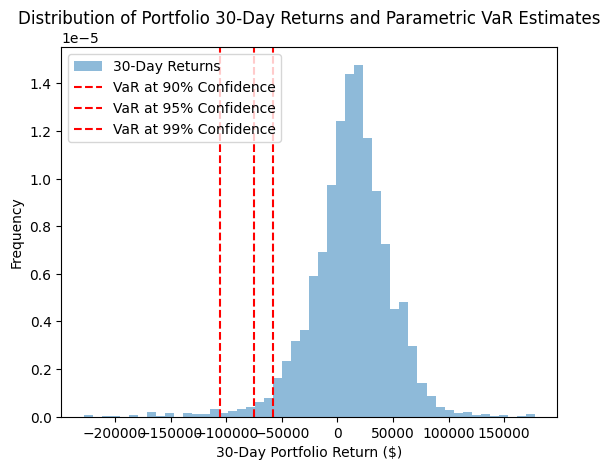

In [12]:
# Convert returns to dollar values for the histogram
historical_x_day_returns_dollar = historical_x_day_returns * portfolio_value

# Plot the histogram
plt.hist(historical_x_day_returns_dollar, bins=50, density=True, alpha=0.5, label=f'{days}-Day Returns')

# Add vertical lines representing VaR at each confidence level
for cl, VaR in zip(confidence_levels, VaRs):
    plt.axvline(x=-VaR, linestyle='--', color='r', label='VaR at {}% Confidence'.format(int(cl * 100)))

plt.xlabel(f'{days}-Day Portfolio Return ($)')
plt.ylabel('Frequency')
plt.title(f'Distribution of Portfolio {days}-Day Returns and Parametric VaR Estimates')
plt.legend()
plt.show()

## Expected Shortfall (Parametric)
Under the normal assumption, ES = portfolio value x sigma x phi(z) / (1 - confidence), with sigma scaled to the 30-day horizon.

In [13]:
ESs = []
for cl in confidence_levels:
    z = norm.ppf(cl)
    ES = portfolio_value * portfolio_std_dev * np.sqrt(days / 252) * norm.pdf(z) / (1 - cl)
    ESs.append(ES)

print(f'{"Confidence":<12}{"30-day VaR":>16}{"30-day ES":>16}')
for cl, v, e in zip(confidence_levels, VaRs, ESs):
    print(f'{cl:<12.0%}{v:>16,.2f}{e:>16,.2f}')

Confidence        30-day VaR       30-day ES
90%                58,299.46       79,836.49
95%                74,826.54       93,835.50
99%               105,828.61      121,244.08
